<h1>Final Project: Part 1 <br> Linear Regression Model</h1>
<h3><b>Phase 1</b></h3>
Code needed for both Part 1 and Part 2 of the final project.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, precision_score, accuracy_score, f1_score, recall_score, ConfusionMatrixDisplay

In [2]:
def display_extreme_values(df, column):
    min_value = df[column].min()
    average = df[column].mean()
    max_value = df[column].max()
    
    print(f"Extreme values for '{column}':")
    print(f"Minimum: {min_value}")
    print(f"Average: {average}")
    print(f"Maximum: {max_value}")

In [3]:
def draw_boxplot(data):
    num_cols = data.select_dtypes(include="number").columns
    plt.figure(figsize=(15, 5)).set_facecolor("#919fbb")

    for i in range(len(num_cols)):
        plt.subplot(2, len(num_cols)//2 + len(num_cols)%2, i + 1, facecolor="#919fbb")
        sns.boxplot(y=data[num_cols[i]])
        plt.title(num_cols[i])
        plt.tight_layout()

In [4]:
def draw_hist(data):
    num_cols = data.select_dtypes(include="number").columns
    plt.figure(figsize=(15, 5)).set_facecolor("#919fbb")

    for i in range(len(num_cols)):
        plt.subplot(2, len(num_cols)//2 + len(num_cols)%2, i + 1, facecolor="#919fbb")
        sns.histplot(data[num_cols[i]], bins=50, kde=True)
        plt.title(num_cols[i])
        plt.tight_layout()

In [5]:
def handle_right_skewness(data, columns):
    for col in columns:
        if data[col].skew() > 1:
            data[col] = np.log1p(data[col])
    return data

In [6]:
def show_unique_values(data, columns=None):
    unique_values=[]
    for column in data.columns:
        if column in columns:
            unique_values.append(f"Unique values in {column}: {data[column].unique()}")
    return unique_values

In [7]:
def show_unique_units(data):
    unique_units=[]
    unique_units.append(data.str.split(' ').str[1].unique())
    return [f"Unique units in {data.name}: {unique_units[0]}" ]

In [8]:
cars = pd.read_csv('Car details v3.csv')

<h3 style="color:Yellow"><b>Getting information about the data:</b></h3>


In [9]:
cars.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8128 entries, 0 to 8127
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   name           8128 non-null   object 
 1   year           8128 non-null   int64  
 2   selling_price  8128 non-null   int64  
 3   km_driven      8128 non-null   int64  
 4   fuel           8128 non-null   object 
 5   seller_type    8128 non-null   object 
 6   transmission   8128 non-null   object 
 7   owner          8128 non-null   object 
 8   mileage        7907 non-null   object 
 9   engine         7907 non-null   object 
 10  max_power      7913 non-null   object 
 11  torque         7906 non-null   object 
 12  seats          7907 non-null   float64
dtypes: float64(1), int64(3), object(9)
memory usage: 825.6+ KB


In [10]:
cars.describe()

,year,selling_price,km_driven,seats
count,8128.000000,8.128000e+03,8.128000e+03,7907.000000
mean,2013.804011,6.382718e+05,6.981951e+04,5.416719
std,4.044249,8.062534e+05,5.655055e+04,0.959588
min,1983.000000,2.999900e+04,1.000000e+00,2.000000
25%,2011.000000,2.549990e+05,3.500000e+04,5.000000
50%,2015.000000,4.500000e+05,6.000000e+04,5.000000
75%,2017.000000,6.750000e+05,9.800000e+04,5.000000
max,2020.000000,1.000000e+07,2.360457e+06,14.000000


<h1 style="color: #ff0000;"><b>Notes:</b></h1>

- <h3 style="color: #ff0000;">mileage, engine, max_power, torque need datatype conversion and have missing values.</h3>
- <h3 style="color: #ff0000;">km_driven includes a value of 1.</h3>


<h3 style="color:Yellow"><b>Seeing a sample of the data to understand the values (measuring units, formatting, etc.), instead of just knowing the datatypes:</b></h3>


In [11]:
cars.head(15)

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.4 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm,5.0
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14 kmpl,1498 CC,103.52 bhp,250Nm@ 1500-2500rpm,5.0
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.7 kmpl,1497 CC,78 bhp,"12.7@ 2,700(kgm@ rpm)",5.0
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.0 kmpl,1396 CC,90 bhp,22.4 kgm at 1750-2750rpm,5.0
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.1 kmpl,1298 CC,88.2 bhp,"11.5@ 4,500(kgm@ rpm)",5.0
5,Hyundai Xcent 1.2 VTVT E Plus,2017,440000,45000,Petrol,Individual,Manual,First Owner,20.14 kmpl,1197 CC,81.86 bhp,113.75nm@ 4000rpm,5.0
6,Maruti Wagon R LXI DUO BSIII,2007,96000,175000,LPG,Individual,Manual,First Owner,17.3 km/kg,1061 CC,57.5 bhp,"7.8@ 4,500(kgm@ rpm)",5.0
7,Maruti 800 DX BSII,2001,45000,5000,Petrol,Individual,Manual,Second Owner,16.1 kmpl,796 CC,37 bhp,59Nm@ 2500rpm,4.0
8,Toyota Etios VXD,2011,350000,90000,Diesel,Individual,Manual,First Owner,23.59 kmpl,1364 CC,67.1 bhp,170Nm@ 1800-2400rpm,5.0
9,Ford Figo Diesel Celebration Edition,2013,200000,169000,Diesel,Individual,Manual,First Owner,20.0 kmpl,1399 CC,68.1 bhp,160Nm@ 2000rpm,5.0


### Cleaning step 1: duplicates and missing values

- 1,202 rows (14.79%) are exact duplicates, so they are dropped.
- After that, about 3% of rows have missing values in `mileage`, `engine`, `max_power`, `torque` and `seats`. They are filled later, after the train/test split.


In [12]:
dropped_percent = (cars.duplicated().sum()/len(cars))*100
print(f"Total duplicated values: {cars.duplicated().sum()}, resembling {dropped_percent:.2f}% of the dataset.")

Total duplicated values: 1202, resembling 14.79% of the dataset.


<p style="color: #ff0000;">14.79% isn't a small share, but according to the dataset's nature, for a row to be duplicated, all of its values must be the same as another row's values. This is statistically unlikely knowing that there are many unique combinations of values in the dataset, so we can drop the duplicates to avoid duplicate bias.</p>


In [13]:
cars = cars.drop_duplicates()
cars.info()

<class 'pandas.core.frame.DataFrame'>
Index: 6926 entries, 0 to 8125
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   name           6926 non-null   object 
 1   year           6926 non-null   int64  
 2   selling_price  6926 non-null   int64  
 3   km_driven      6926 non-null   int64  
 4   fuel           6926 non-null   object 
 5   seller_type    6926 non-null   object 
 6   transmission   6926 non-null   object 
 7   owner          6926 non-null   object 
 8   mileage        6718 non-null   object 
 9   engine         6718 non-null   object 
 10  max_power      6721 non-null   object 
 11  torque         6717 non-null   object 
 12  seats          6718 non-null   float64
dtypes: float64(1), int64(3), object(9)
memory usage: 757.5+ KB


In [14]:
print(f"Details of missing values:\n{cars.isnull().sum()}\n\n")
print(f"Total missing values: {cars.isnull().sum().sum()}\n")
print(f"Percentage of rows with missing values: {cars.isnull().any(axis=1).sum()/len(cars)*100:.2f}%")

Details of missing values:
name               0
year               0
selling_price      0
km_driven          0
fuel               0
seller_type        0
transmission       0
owner              0
mileage          208
engine           208
max_power        205
torque           209
seats            208
dtype: int64


Total missing values: 1038

Percentage of rows with missing values: 3.02%


### Check ranges and categories

Look at the min / average / max of each numeric column and the unique values of the categorical ones. The `units` check shows what text needs to be removed from `mileage`, `max_power` and `engine`.


In [15]:
for col in cars.select_dtypes(include=[np.number]).columns:
    if col != 'name':
        display_extreme_values(cars, col)

Extreme values for 'year':
Minimum: 1983
Average: 2013.4203003176438
Maximum: 2020
Extreme values for 'selling_price':
Minimum: 29999
Average: 517270.6784579844
Maximum: 10000000
Extreme values for 'km_driven':
Minimum: 1
Average: 73995.67643661566
Maximum: 2360457
Extreme values for 'seats':
Minimum: 2.0
Average: 5.4346531705864844
Maximum: 14.0


In [16]:
show_unique_values(cars, columns=['fuel', 'seller_type', 'transmission', 'owner', 'seats'])

["Unique values in fuel: ['Diesel' 'Petrol' 'LPG' 'CNG']",
 "Unique values in seller_type: ['Individual' 'Dealer' 'Trustmark Dealer']",
 "Unique values in transmission: ['Manual' 'Automatic']",
 "Unique values in owner: ['First Owner' 'Second Owner' 'Third Owner' 'Fourth & Above Owner'\n 'Test Drive Car']",
 'Unique values in seats: [ 5.  4. nan  7.  8.  6.  9. 10. 14.  2.]']

In [17]:
# display head to view the columns that need datatype conversion to easen the data cleaning process and the model training process carried out later on.
cars[['mileage', 'max_power', 'engine', 'torque']].head(15)

,mileage,max_power,engine,torque
0,23.4 kmpl,74 bhp,1248 CC,190Nm@ 2000rpm
1,21.14 kmpl,103.52 bhp,1498 CC,250Nm@ 1500-2500rpm
2,17.7 kmpl,78 bhp,1497 CC,"12.7@ 2,700(kgm@ rpm)"
3,23.0 kmpl,90 bhp,1396 CC,22.4 kgm at 1750-2750rpm
4,16.1 kmpl,88.2 bhp,1298 CC,"11.5@ 4,500(kgm@ rpm)"
5,20.14 kmpl,81.86 bhp,1197 CC,113.75nm@ 4000rpm
6,17.3 km/kg,57.5 bhp,1061 CC,"7.8@ 4,500(kgm@ rpm)"
7,16.1 kmpl,37 bhp,796 CC,59Nm@ 2500rpm
8,23.59 kmpl,67.1 bhp,1364 CC,170Nm@ 1800-2400rpm
9,20.0 kmpl,68.1 bhp,1399 CC,160Nm@ 2000rpm


In [18]:
print(show_unique_units(cars['mileage']))
print(show_unique_units(cars['max_power']))
print(show_unique_units(cars['engine']))

["Unique units in mileage: ['kmpl' 'km/kg' nan]"]
["Unique units in max_power: ['bhp' nan]"]
["Unique units in engine: ['CC' nan]"]


### Convert text columns to numbers

- **mileage:** remove the unit. Values in `km/kg` (CNG/LPG cars) are multiplied by 1.4 to approximate `kmpl`.
- **max_power, engine:** remove the unit (`bhp`, `CC`).
- **torque:** values are in either `Nm` or `kgm`. Everything is converted to Nm (1 kgm = 9.80665 Nm) as `torque_val`, and the rpm is saved as `max_rpm` (upper end if it is a range). The original `torque` column is dropped.


In [19]:
mil_val = cars['mileage'].str.split(' ').str[0].astype(float)
mil_unit = cars['mileage'].str.split(' ').str[1]

mil_val[mil_unit == 'km/kg'] *= 1.4
cars['mileage'] = mil_val

#max_power and engine don't need unit conversion. convert to numeric values.
cars['max_power'] = pd.to_numeric(cars['max_power'].str.split(' ').str[0], errors='coerce')
cars['engine'] = pd.to_numeric(cars['engine'].str.split(' ').str[0], errors='coerce')

In [20]:
cars['torque'] = cars['torque'].str.replace(',', '')

torque = cars['torque']

is_kgm = (torque.str.lower().str.extract(r'(kgm|nm)')[0] == 'kgm')
torque_val = torque.str.extract(r'(\d+\.?\d*)')[0].astype(float)
torque_val[is_kgm] *= 9.80665
cars['torque_val'] = torque_val

rpm = torque.str.extract(r'(\d{4,})(?:\D+(\d{4,}))?')
cars['max_rpm'] = rpm[1].astype(float).fillna(rpm[0].astype(float))

cars.drop(columns=['torque'], inplace=True)

### Invalid `km_driven`

A car with 1 km driven is not realistic, so that value is set to missing and filled later.


In [21]:
cars['km_driven'].nsmallest(20)

7913       1
399     1000
2963    1000
6638    1000
7429    1000
7492    1000
6163    1300
130     1303
583     1500
2298    1500
1989    1600
922     1620
264     2000
268     2000
388     2000
1912    2000
1996    2000
5389    2000
7332    2000
1375    2118
Name: km_driven, dtype: int64

In [22]:
cars['km_driven'] = cars['km_driven'].replace(1, np.nan)

### Outliers

Boxplots are drawn before and after removing outlier values:

- `km_driven` above 1,000,000
- `max_power` of 0 or more than 400
- `mileage` of 0 or less
- `max_rpm` of 20,000 or more

This removes 22 rows.


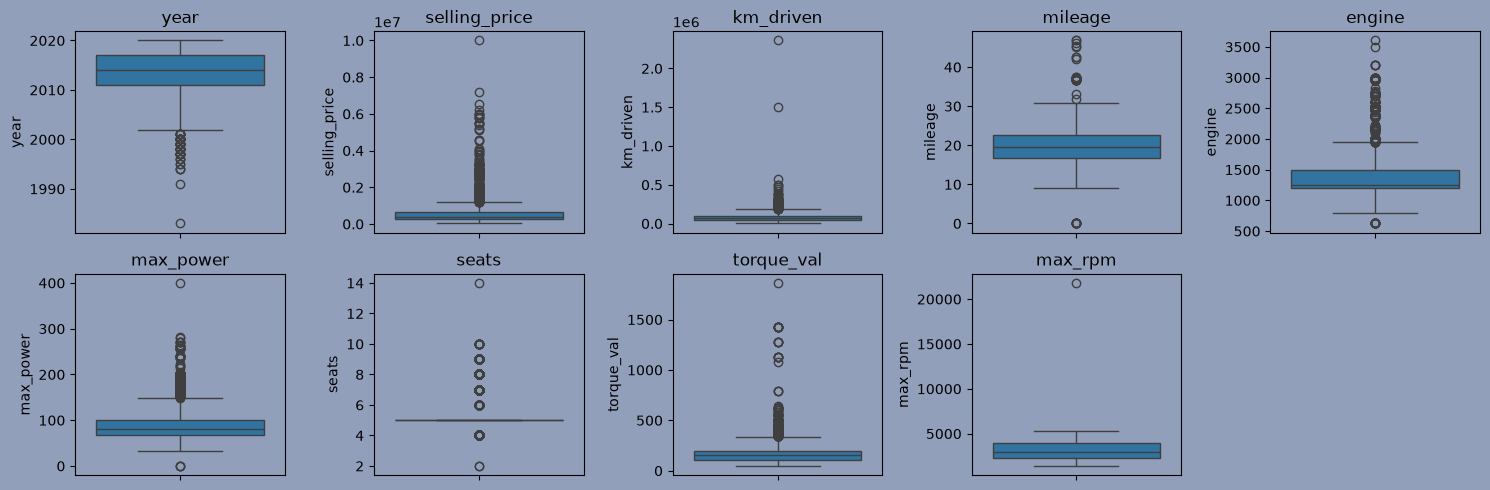

In [23]:
draw_boxplot(cars)

In [24]:
outliers = (
    (cars['km_driven'] > 1000000)
    | (cars['max_power'] <= 0) | (cars['max_power'] >= 400)
    | (cars['mileage'] <= 0)
    | (cars['max_rpm'] >= 20000)
)
cars = cars[~outliers]

Drawing boxplot for cars after removing outliers from 22 rows of data.


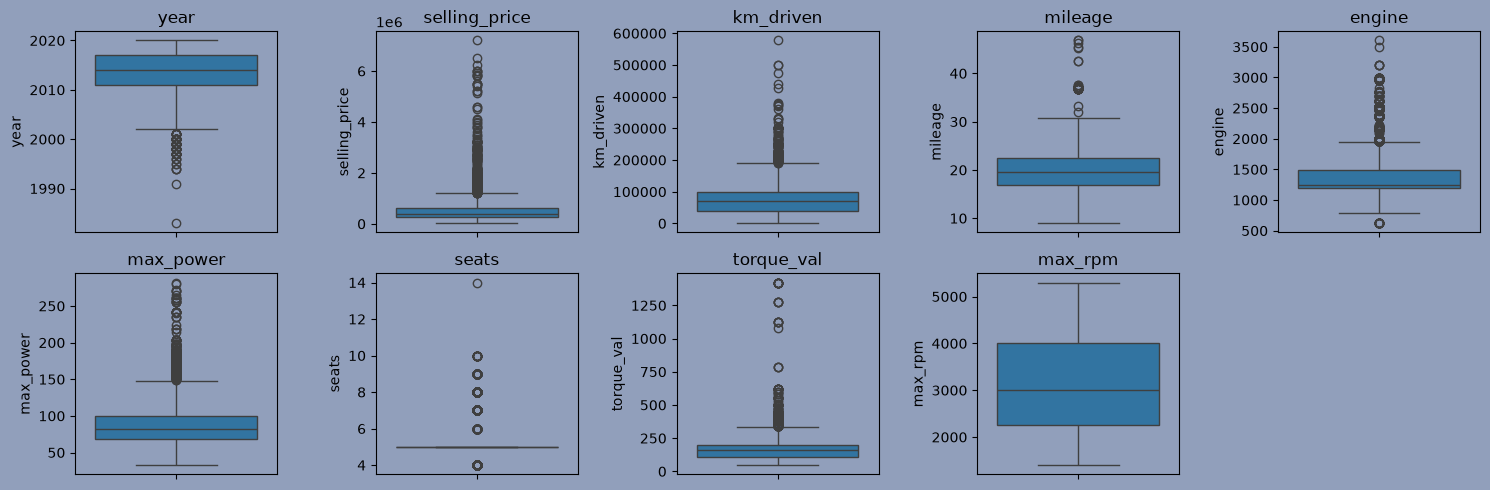

In [25]:
print(f"Drawing boxplot for cars after removing outliers from {outliers.sum()} rows of data.")
draw_boxplot(cars)

In [26]:
cars.info()

<class 'pandas.core.frame.DataFrame'>
Index: 6904 entries, 0 to 8125
Data columns (total 14 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   name           6904 non-null   object 
 1   year           6904 non-null   int64  
 2   selling_price  6904 non-null   int64  
 3   km_driven      6903 non-null   float64
 4   fuel           6904 non-null   object 
 5   seller_type    6904 non-null   object 
 6   transmission   6904 non-null   object 
 7   owner          6904 non-null   object 
 8   mileage        6699 non-null   float64
 9   engine         6699 non-null   float64
 10  max_power      6698 non-null   float64
 11  seats          6699 non-null   float64
 12  torque_val     6698 non-null   float64
 13  max_rpm        6694 non-null   float64
dtypes: float64(7), int64(2), object(5)
memory usage: 809.1+ KB


In [27]:
cars.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,seats,torque_val,max_rpm
0,Maruti Swift Dzire VDI,2014,450000,145500.0,Diesel,Individual,Manual,First Owner,23.40,1248.0,74.00,5.0,190.000000,2000.0
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000.0,Diesel,Individual,Manual,Second Owner,21.14,1498.0,103.52,5.0,250.000000,2500.0
2,Honda City 2017-2020 EXi,2006,158000,140000.0,Petrol,Individual,Manual,Third Owner,17.70,1497.0,78.00,5.0,124.544455,2700.0
3,Hyundai i20 Sportz Diesel,2010,225000,127000.0,Diesel,Individual,Manual,First Owner,23.00,1396.0,90.00,5.0,219.668960,2750.0
4,Maruti Swift VXI BSIII,2007,130000,120000.0,Petrol,Individual,Manual,First Owner,16.10,1298.0,88.20,5.0,112.776475,4500.0


### Feature engineering

- `brand` is the first word of `name` (so "Land Rover" appears as "Land").
- `age` = 2026 - `year`.
- `name` and `year` are dropped because they are replaced by `brand` and `age`.


In [28]:
cars['brand'] = cars['name'].str.split(' ').str[0]
cars['age'] = 2026 - cars['year']
cars.drop(columns=['name', 'year'], inplace=True)

### Skewness

Histograms show which columns are right-skewed. Columns with skew above 1 get a `log1p` transform. `selling_price` is also log-transformed, so predictions must be converted back with `expm1` at the end.


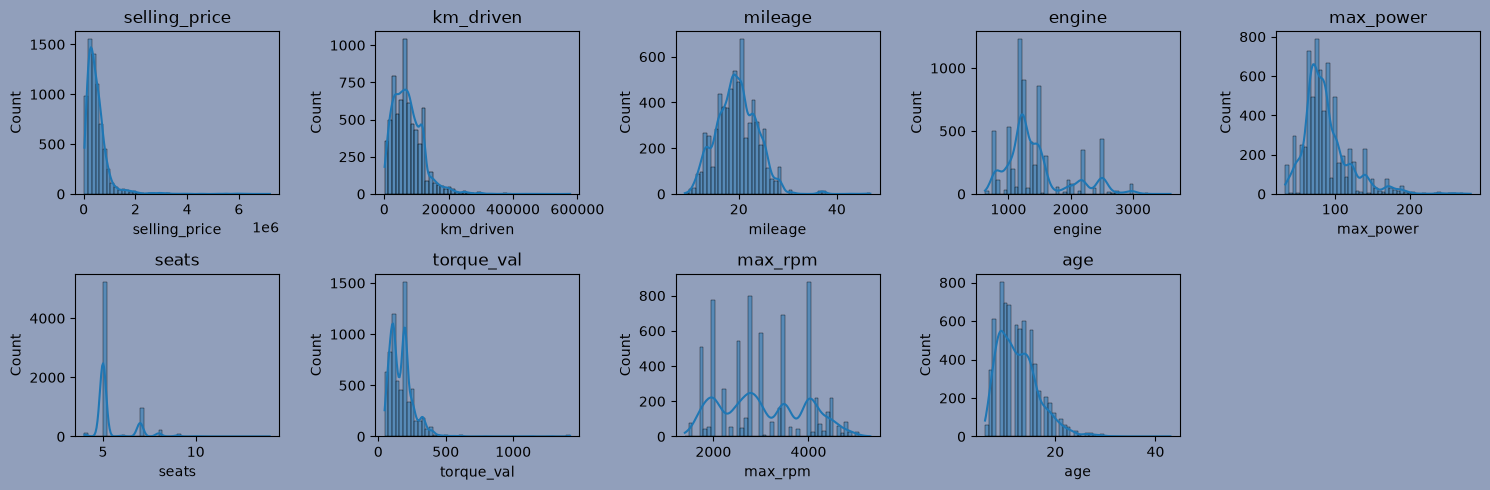

In [29]:
draw_hist(cars)

In [30]:
skew = cars[['km_driven', 'mileage', 'engine', 'max_power', 'torque_val', 'age']].skew()
skewed_cols = skew[skew > 1].index
unskewed_data = handle_right_skewness(cars, skewed_cols)
cars['selling_price'] = np.log1p(cars['selling_price'])

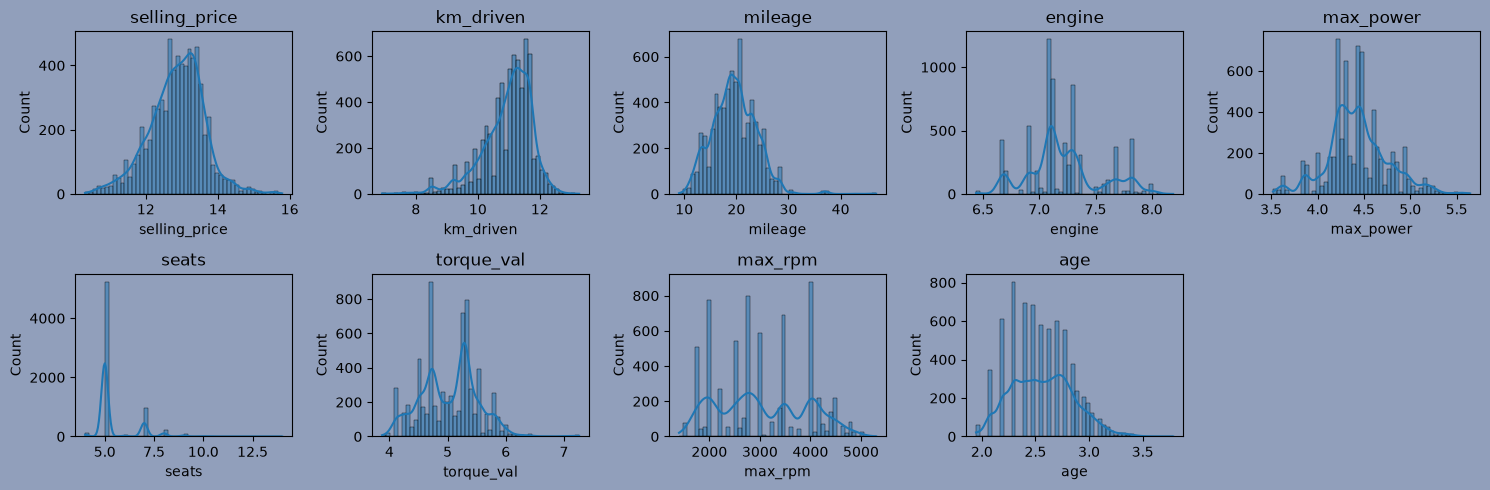

In [31]:
draw_hist(unskewed_data)

### Exploring the data

- Typical selling price by **brand** and by **owner** (computed as `expm1` of the mean log price). Test Drive cars are by far the most expensive, and price drops as the number of owners goes up.
- Correlation heatmap of the numeric columns.
- Pie chart of the fuel type distribution.


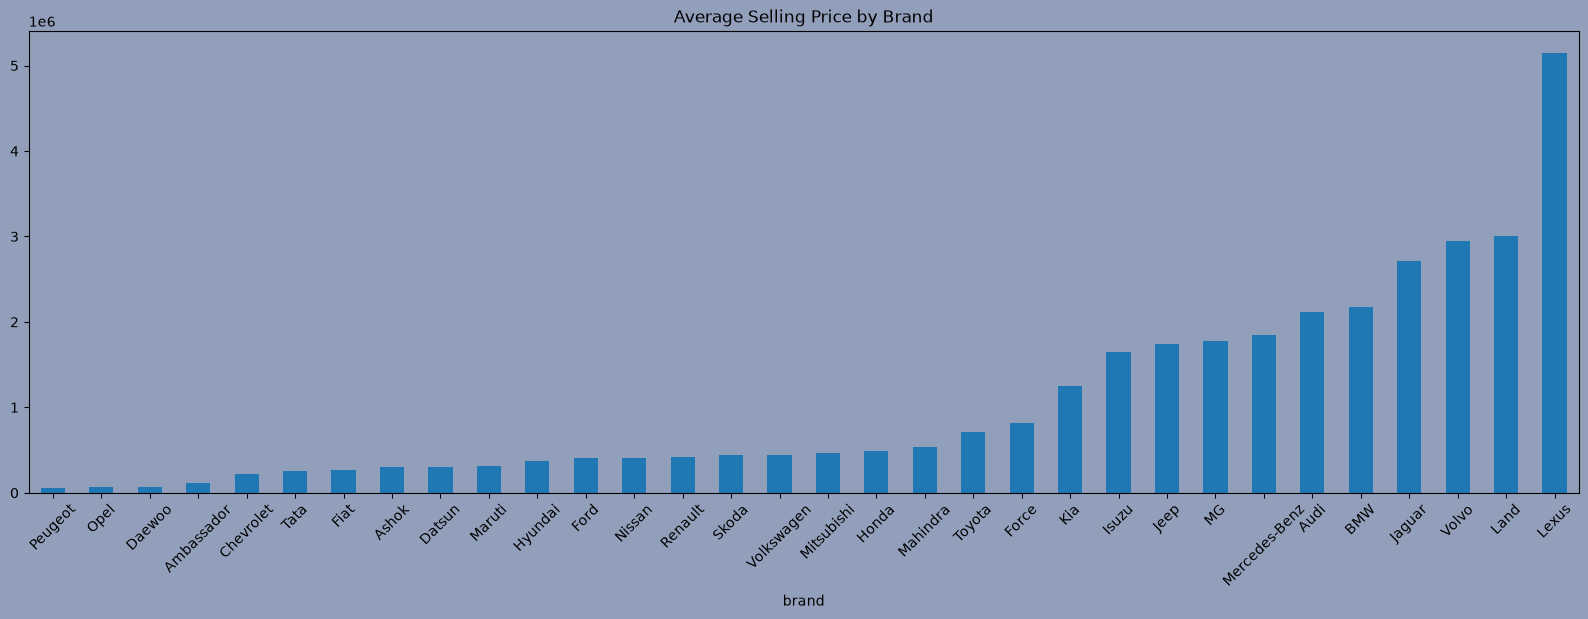

In [32]:
plt.figure().set_facecolor("#919fbb")
plt.gca().set_facecolor("#919fbb")
np.expm1(cars.groupby('brand')['selling_price'].mean().sort_values()).plot(kind='bar', figsize=(20, 6), title='Average Selling Price by Brand', rot=45)
plt.show()

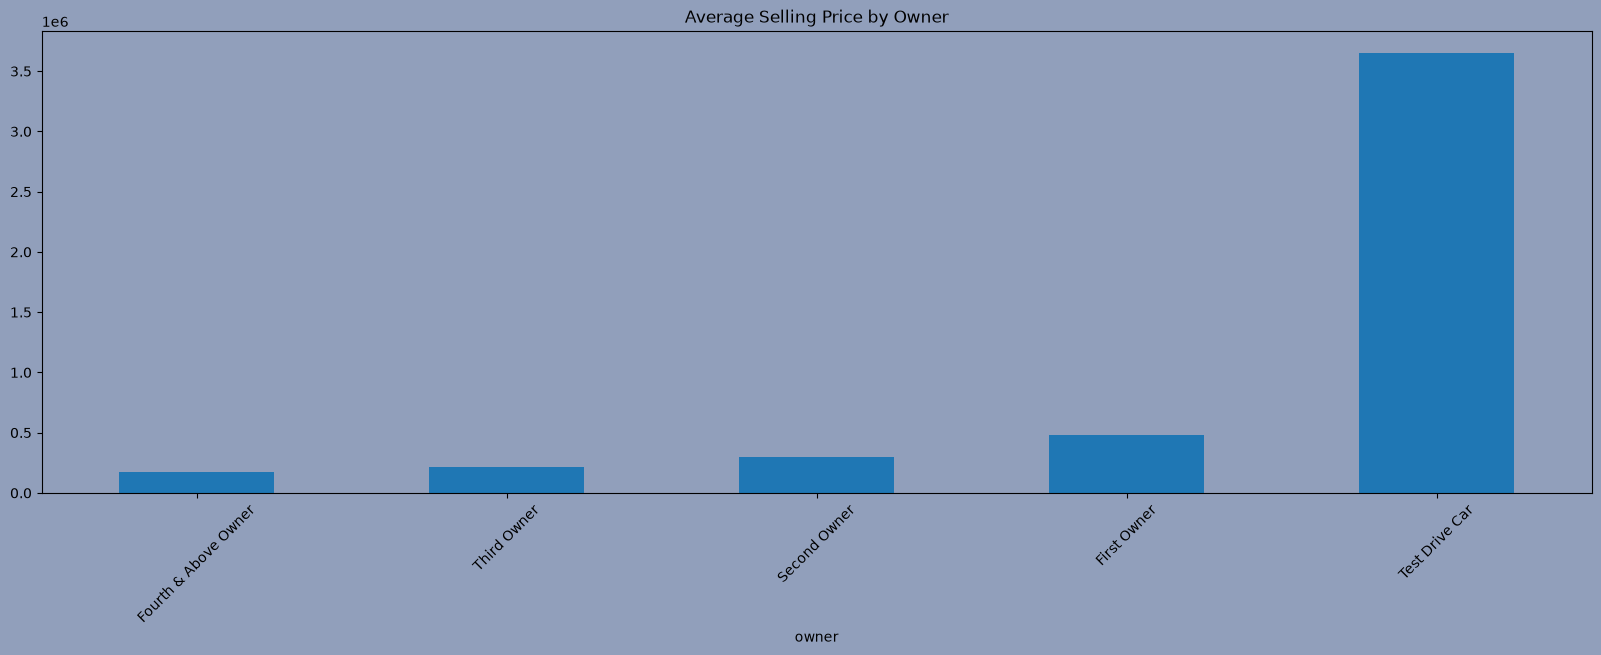

In [33]:
plt.figure().set_facecolor("#919fbb")
plt.gca().set_facecolor("#919fbb")
np.expm1(cars.groupby('owner')['selling_price'].mean().sort_values()).plot(kind='bar', figsize=(20, 6), title='Average Selling Price by Owner', rot=45)
plt.show()

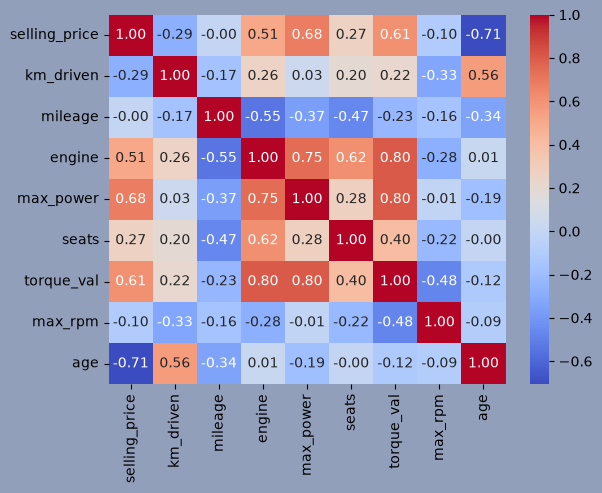

In [34]:
numeric_cars = cars.select_dtypes(include="number")
correlation_matrix = numeric_cars.corr()
corr_by_price = correlation_matrix['selling_price'].sort_values(ascending=False)

plt.figure().set_facecolor("#919fbb")
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.show()

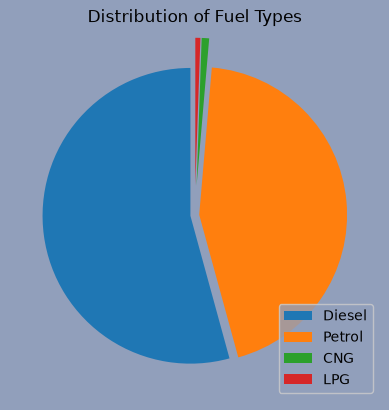

In [35]:
plt.figure().set_facecolor("#919fbb")
plt.gca().set_facecolor("#919fbb")
plt.pie(cars['fuel'].value_counts(), startangle=90, explode=(0.03, 0.03, 0.2, 0.2))
plt.title('Distribution of Fuel Types')
plt.legend(cars['fuel'].value_counts().index, facecolor="#919fbb")
plt.show()

### Encoding

- `owner` is ordinal: Test Drive Car = 0, First = 1, Second = 2, Third = 3, Fourth & Above = 4. This order follows the price trend in the chart above.
- `brand`, `fuel`, `seller_type` and `transmission` are one-hot encoded with `drop_first=True`.


In [36]:
encoded_owner = {'Test Drive Car': 0,
                 'First Owner': 1,
                 'Second Owner': 2,
                 'Third Owner': 3,
                 'Fourth & Above Owner': 4                 
                 }
cars['owner'] = cars['owner'].map(encoded_owner)

cars = pd.get_dummies(cars, columns=['brand', 'fuel', 'seller_type', 'transmission'], drop_first=True)

### Train/test split

80% training, 20% testing (`random_state=42`). The target is the log of `selling_price`.


In [37]:
X = cars.drop(columns=['selling_price'])
y = cars['selling_price']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

### Fill missing values

Missing values are filled **after** the split, using only training-set statistics, so nothing from the test set leaks into training:

- `seats`: most common value
- `km_driven`, `engine`, `max_rpm`: median
- `mileage`, `max_power`, `torque_val`: mean

The next cell removes rows with a missing target. `selling_price` has no missing values, so nothing is removed.


In [38]:
X_train['seats'] = X_train['seats'].fillna(X_train['seats'].mode()[0])
X_test['seats'] = X_test['seats'].fillna(X_train['seats'].mode()[0])


X_train['km_driven'] = X_train['km_driven'].fillna(X_train['km_driven'].median())
X_test['km_driven'] = X_test['km_driven'].fillna(X_train['km_driven'].median())

for col in ['engine', 'max_rpm']:
    X_train[col] = X_train[col].fillna(X_train[col].median())
    X_test[col] = X_test[col].fillna(X_train[col].median())

for col in ['mileage', 'max_power', 'torque_val']:
    X_train[col] = X_train[col].fillna(X_train[col].mean())
    X_test[col] = X_test[col].fillna(X_train[col].mean())

In [39]:
X_train = X_train[y_train.notnull()]
X_test = X_test[y_test.notnull()]
y_train = y_train[y_train.notnull()]
y_test = y_test[y_test.notnull()]

### Scaling and linear regression

Features are standardized (scaler fitted on the training set only), then a `LinearRegression` model is trained. Predictions and test values are converted back with `expm1`, so the errors are in real price units.


In [40]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

model = LinearRegression()
model.fit(X_train_scaled, y_train)
y_pred = np.expm1(model.predict(X_test_scaled))
y_test = np.expm1(y_test)

### Evaluation

The scatter plot compares actual and predicted prices (points close to the red dashed line are good predictions). Then MAE, MSE, RMSE and R-squared are calculated.


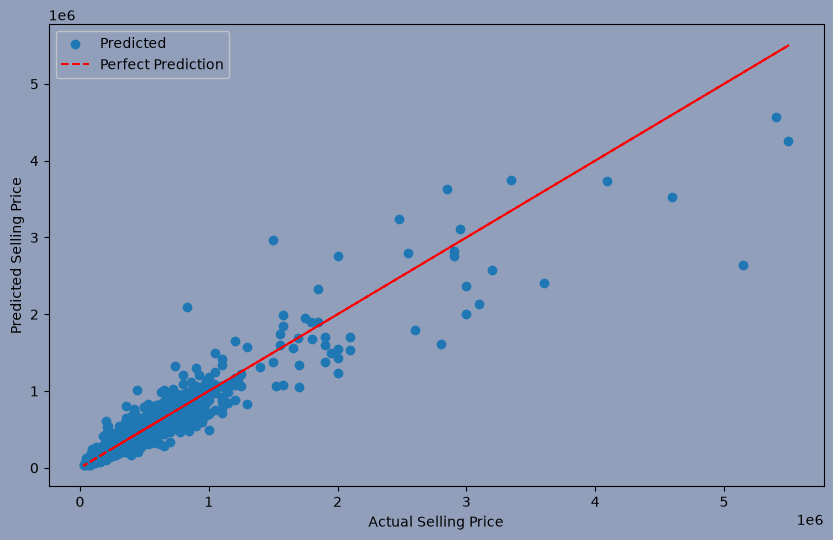

In [41]:
plt.figure(figsize=(10, 6), facecolor="#919fbb")
plt.gca().set_facecolor("#919fbb")
plt.scatter(y_test, y_pred)
plt.plot(y_test, y_test, color="red", linestyle="--")
plt.xlabel("Actual Selling Price")
plt.ylabel("Predicted Selling Price")
plt.legend(["Predicted", "Perfect Prediction"], facecolor="#919fbb")
plt.show()

In [42]:
print(f"Mean Absolute Error: {mean_absolute_error(y_test, y_pred)}")
print(f"Mean Squared Error: {mean_squared_error(y_test, y_pred)}")
print(f"Root Mean Squared Error: {np.sqrt(mean_squared_error(y_test, y_pred))}")
print(f"R-squared: {r2_score(y_test, y_pred)}")

Mean Absolute Error: 94437.79689043424
Mean Squared Error: 30020610106.51217
Root Mean Squared Error: 173264.56679457624
R-squared: 0.8724153182992138


<h1>Final Project: Part 2</h1>
<h3><b>Phase 1</b></h3>
EDA.


### Load the data (Part 2: airline passenger satisfaction)

**Goal:** classify a passenger as **satisfied (1)** or **neutral or dissatisfied (0)** using **logistic regression**.


In [43]:
df = pd.read_csv('airline_passenger_satisfaction_m.csv')

In [44]:
df.head()

,Gender,customer_type,age,type_of_travel,customer_class,flight_distance,inflight_wifi_service,ease_of_online_booking,online_boarding,seat_comfort,inflight_entertainment,onboard_service,leg_room_service,baggage_handling,cleanliness,departure_delay_in_minutes,arrival_delay_in_minutes,satisfaction
0,Male,Loyal Customer,18.0,Personal Travel,Eco Plus,545.0,4.0,4.0,4.0,NaN,3.0,NaN,2.0,3.0,2.0,54.0,54.0,satisfied
1,Female,Loyal Customer,NaN,Personal Travel,Business,1063.0,3.0,3.0,2.0,3.0,4.0,4.0,4.0,NaN,2.0,13.0,19.0,neutral or dissatisfied
2,Female,Loyal Customer,47.0,Business travel,Business,1533.0,4.0,3.0,5.0,3.0,5.0,4.0,3.0,5.0,3.0,20.0,12.0,satisfied
3,Male,Loyal Customer,30.0,Business travel,Business,585.0,5.0,5.0,3.0,5.0,5.0,5.0,5.0,5.0,NaN,5.0,5.0,satisfied
4,Male,Loyal Customer,25.0,Business travel,Business,NaN,3.0,2.0,2.0,3.0,2.0,1.0,3.0,3.0,3.0,0.0,5.0,neutral or dissatisfied


In [45]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8440 entries, 0 to 8439
Data columns (total 18 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Gender                      8016 non-null   object 
 1   customer_type               7960 non-null   object 
 2   age                         7590 non-null   float64
 3   type_of_travel              7830 non-null   object 
 4   customer_class              7944 non-null   object 
 5   flight_distance             7695 non-null   float64
 6   inflight_wifi_service       7391 non-null   float64
 7   ease_of_online_booking      7528 non-null   float64
 8   online_boarding             7590 non-null   float64
 9   seat_comfort                7797 non-null   float64
 10  inflight_entertainment      7393 non-null   float64
 11  onboard_service             7693 non-null   float64
 12  leg_room_service            7632 non-null   float64
 13  baggage_handling            7765 

In [46]:
df.describe()

,age,flight_distance,inflight_wifi_service,ease_of_online_booking,online_boarding,seat_comfort,inflight_entertainment,onboard_service,leg_room_service,baggage_handling,cleanliness,departure_delay_in_minutes,arrival_delay_in_minutes
count,7590.000000,7695.000000,7391.000000,7528.000000,7590.000000,7797.000000,7393.000000,7693.000000,7632.000000,7765.000000,7659.000000,7300.000000,7155.000000
mean,39.962582,1568.732424,3.490461,3.482067,3.671146,3.683468,3.667388,3.674119,3.688286,3.856407,3.690560,23.692329,26.120335
std,15.864400,1729.616594,1.057423,1.049434,1.079962,1.060315,1.028879,1.019825,1.096296,0.945371,1.013143,133.794041,142.204939
min,0.000000,50.000000,1.000000,1.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,0.000000,0.000000
25%,29.000000,627.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,0.000000,0.000000
50%,39.000000,1104.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,0.000000,4.000000
75%,50.000000,1926.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,5.000000,5.000000,4.000000,14.000000,16.000000
max,120.000000,20000.000000,5.000000,5.000000,10.000000,10.000000,5.000000,5.000000,10.000000,5.000000,5.000000,1800.000000,1800.000000


### Column groups

- `rating_columns`: the 9 survey scores (should be 1 to 5)
- `numeric_cols`: `age`, `flight_distance` and the two delay columns
- `categorical_cols`: text columns, including the target `satisfaction`


In [47]:
rating_columns = ['inflight_wifi_service', 'ease_of_online_booking', 'online_boarding', 'seat_comfort', 'inflight_entertainment', 'onboard_service', 'leg_room_service', 'baggage_handling', 'cleanliness']
numeric_cols = df.select_dtypes(include=[np.number]).columns.drop(rating_columns)
categorical_cols = df.select_dtypes(include=[object]).columns

### Missing values and duplicates

There are 13,542 missing values, and **81.61% of rows** have at least one. Dropping those rows would throw away most of the data, so missing values are filled after the split instead. There are no duplicate rows.


In [48]:
print(f"Details of missing values:\n{df.isnull().sum()}\n\n")
print(f"Total missing values: {df.isnull().sum().sum()}\n")
print(f"Percentage of rows with missing values: {df.isnull().any(axis=1).sum()/len(df)*100:.2f}%")

Details of missing values:
Gender                         424
customer_type                  480
age                            850
type_of_travel                 610
customer_class                 496
flight_distance                745
inflight_wifi_service         1049
ease_of_online_booking         912
online_boarding                850
seat_comfort                   643
inflight_entertainment        1047
onboard_service                747
leg_room_service               808
baggage_handling               675
cleanliness                    781
departure_delay_in_minutes    1140
arrival_delay_in_minutes      1285
satisfaction                     0
dtype: int64


Total missing values: 13542

Percentage of rows with missing values: 81.61%


In [49]:
# cleaning the duplicate rows
print(f"Number of duplicate rows: {df.duplicated().sum()}")

Number of duplicate rows: 0


In [50]:
df.head()

,Gender,customer_type,age,type_of_travel,customer_class,flight_distance,inflight_wifi_service,ease_of_online_booking,online_boarding,seat_comfort,inflight_entertainment,onboard_service,leg_room_service,baggage_handling,cleanliness,departure_delay_in_minutes,arrival_delay_in_minutes,satisfaction
0,Male,Loyal Customer,18.0,Personal Travel,Eco Plus,545.0,4.0,4.0,4.0,NaN,3.0,NaN,2.0,3.0,2.0,54.0,54.0,satisfied
1,Female,Loyal Customer,NaN,Personal Travel,Business,1063.0,3.0,3.0,2.0,3.0,4.0,4.0,4.0,NaN,2.0,13.0,19.0,neutral or dissatisfied
2,Female,Loyal Customer,47.0,Business travel,Business,1533.0,4.0,3.0,5.0,3.0,5.0,4.0,3.0,5.0,3.0,20.0,12.0,satisfied
3,Male,Loyal Customer,30.0,Business travel,Business,585.0,5.0,5.0,3.0,5.0,5.0,5.0,5.0,5.0,NaN,5.0,5.0,satisfied
4,Male,Loyal Customer,25.0,Business travel,Business,NaN,3.0,2.0,2.0,3.0,2.0,1.0,3.0,3.0,3.0,0.0,5.0,neutral or dissatisfied


### Misentered ratings

The boxplots show rating values outside the valid 1 to 5 range (for example 0 and 10). Those values are set to missing (94 extra missing values).


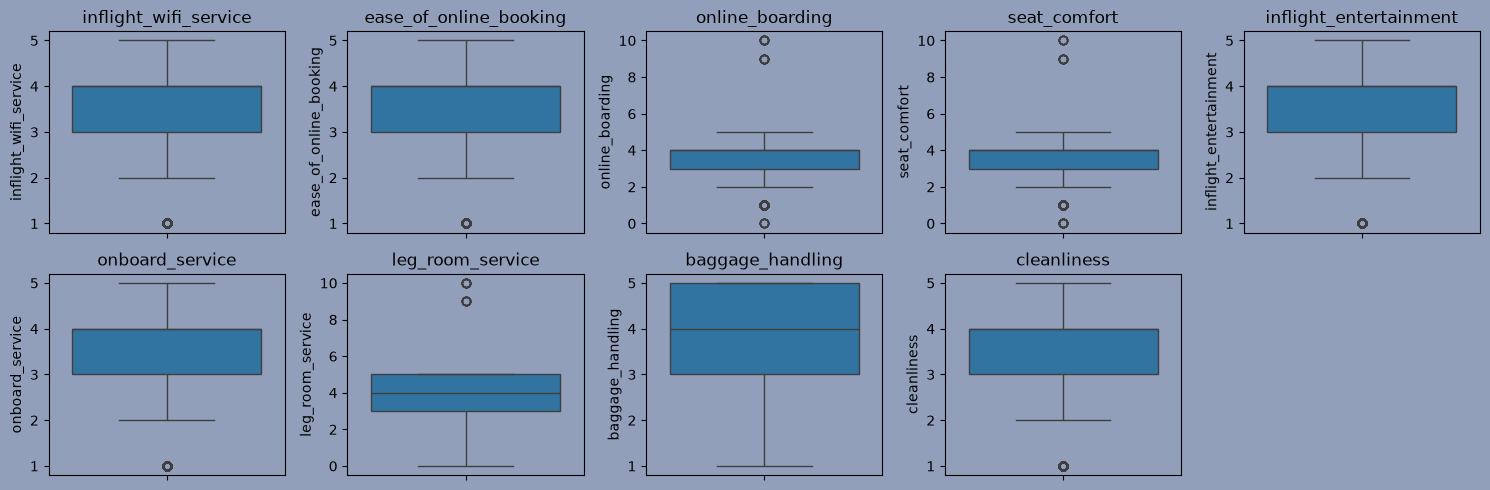

In [51]:
draw_boxplot(df[rating_columns])

In [52]:
print("Number of null values before dropping misentered ratings:", df.isnull().sum().sum())
for col in rating_columns:
    df.loc[~df[col].between(1, 5), col] = np.nan

Number of null values before dropping misentered ratings: 13542


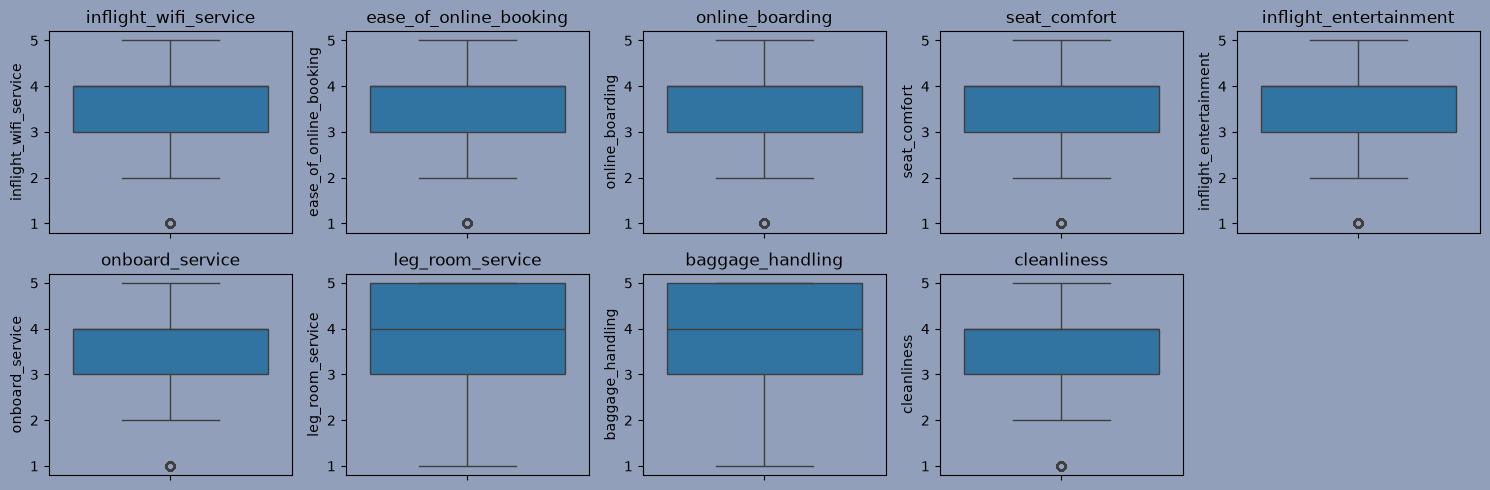

In [53]:
draw_boxplot(df[rating_columns])

In [54]:
print("Number of null values after dropping misentered ratings:", df.isnull().sum().sum())

Number of null values after dropping misentered ratings: 13636


### Misentered numeric values

Only the invalid **value** is set to missing. The rest of the row is kept.

| Column                       | Rule                     | Values removed |
| ---------------------------- | ------------------------ | -------------- |
| `age`                        | below 5 or 100 and above | 53             |
| `flight_distance`            | 10,000 and above         | 55             |
| `departure_delay_in_minutes` | 500 and above            | 75             |
| `arrival_delay_in_minutes`   | 500 and above            | 73             |

The thresholds are judgment calls based on the boxplots.


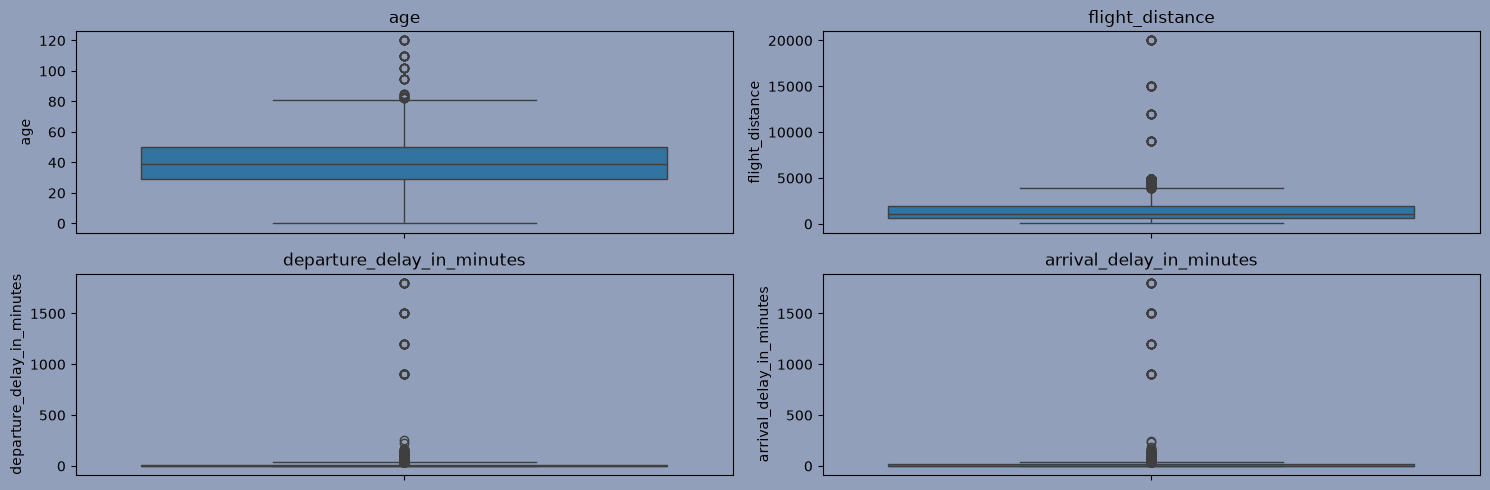

In [55]:
draw_boxplot(df[numeric_cols])

In [56]:
print(f"Number of null values in 'age' column: {df['age'].isnull().sum()}")
df.loc[(df['age'] < 5) | (df['age'] >= 100), 'age'] = np.nan
print(f"Number of null values in 'age' column after dropping misentered values: {df['age'].isnull().sum()}")

Number of null values in 'age' column: 850
Number of null values in 'age' column after dropping misentered values: 903


In [57]:
print(f"Number of null values in 'flight_distance' column: {df['flight_distance'].isnull().sum()}")
df.loc[df['flight_distance'] >= 10000, 'flight_distance'] = np.nan
print(f"Number of null values in 'flight_distance' column after dropping misentered values: {df['flight_distance'].isnull().sum()}")

Number of null values in 'flight_distance' column: 745
Number of null values in 'flight_distance' column after dropping misentered values: 800


In [58]:
print(f"Number of null values in 'departure_delay_in_minutes' column: {df['departure_delay_in_minutes'].isnull().sum()}")
df.loc[df['departure_delay_in_minutes'] >= 500, 'departure_delay_in_minutes'] = np.nan
print(f"Number of null values in 'departure_delay_in_minutes' column after dropping misentered values: {df['departure_delay_in_minutes'].isnull().sum()}")

Number of null values in 'departure_delay_in_minutes' column: 1140
Number of null values in 'departure_delay_in_minutes' column after dropping misentered values: 1215


In [59]:
print(f"Number of null values in 'arrival_delay_in_minutes' column: {df['arrival_delay_in_minutes'].isnull().sum()}")
df.loc[df['arrival_delay_in_minutes'] >= 500, 'arrival_delay_in_minutes'] = np.nan
print(f"Number of null values in 'arrival_delay_in_minutes' column after dropping misentered values: {df['arrival_delay_in_minutes'].isnull().sum()}")

Number of null values in 'arrival_delay_in_minutes' column: 1285
Number of null values in 'arrival_delay_in_minutes' column after dropping misentered values: 1358


In [60]:
df.isnull().sum().sum()

np.int64(13892)

In [61]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8440 entries, 0 to 8439
Data columns (total 18 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Gender                      8016 non-null   object 
 1   customer_type               7960 non-null   object 
 2   age                         7537 non-null   float64
 3   type_of_travel              7830 non-null   object 
 4   customer_class              7944 non-null   object 
 5   flight_distance             7640 non-null   float64
 6   inflight_wifi_service       7391 non-null   float64
 7   ease_of_online_booking      7528 non-null   float64
 8   online_boarding             7559 non-null   float64
 9   seat_comfort                7765 non-null   float64
 10  inflight_entertainment      7393 non-null   float64
 11  onboard_service             7693 non-null   float64
 12  leg_room_service            7601 non-null   float64
 13  baggage_handling            7765 

### Check categories and data types

Check the unique values of the categorical columns before encoding them, and confirm the data types.


In [62]:
show_unique_values(df, columns=categorical_cols)

["Unique values in Gender: ['Male' 'Female' nan]",
 "Unique values in customer_type: ['Loyal Customer' 'disloyal Customer' nan]",
 "Unique values in type_of_travel: ['Personal Travel' 'Business travel' nan]",
 "Unique values in customer_class: ['Eco Plus' 'Business' nan 'Eco']",
 "Unique values in satisfaction: ['satisfied' 'neutral or dissatisfied']"]

In [63]:
df.dtypes

Gender                         object
customer_type                  object
age                           float64
type_of_travel                 object
customer_class                 object
flight_distance               float64
inflight_wifi_service         float64
ease_of_online_booking        float64
online_boarding               float64
seat_comfort                  float64
inflight_entertainment        float64
onboard_service               float64
leg_room_service              float64
baggage_handling              float64
cleanliness                   float64
departure_delay_in_minutes    float64
arrival_delay_in_minutes      float64
satisfaction                   object
dtype: object

### Skewness

Histograms of the numeric columns, then `log1p` on `flight_distance` and the delay columns if their skew is above 1.


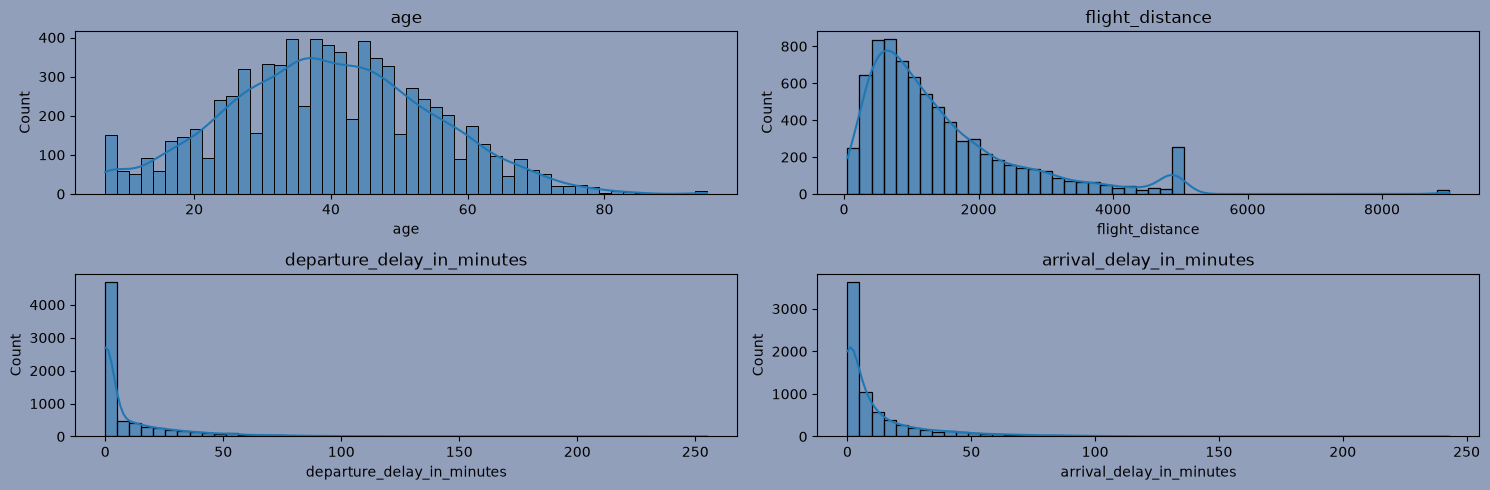

In [64]:
draw_hist(df[numeric_cols])

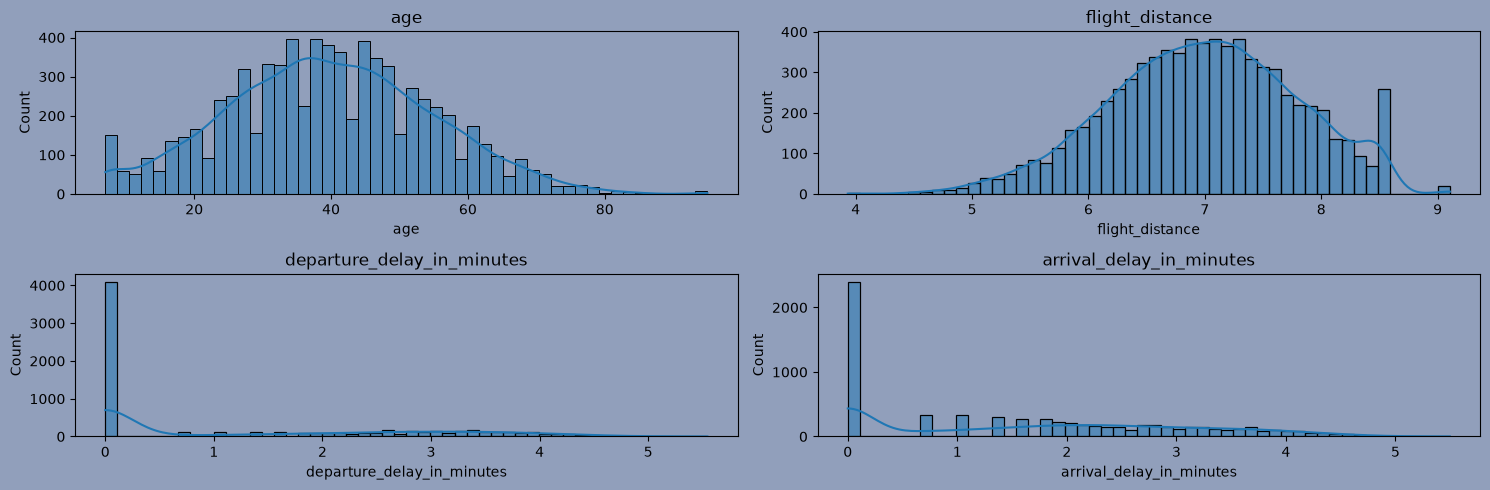

In [65]:
skew = df[['flight_distance', 'departure_delay_in_minutes', 'arrival_delay_in_minutes']].skew()
skewed_cols = skew[skew > 1].index
unskewed_data = handle_right_skewness(df, skewed_cols)
draw_hist(unskewed_data[numeric_cols])

### Visual exploration

- Pie chart of the satisfaction classes (shows how balanced the target is).
- Count plot of `customer_class` split by satisfaction.


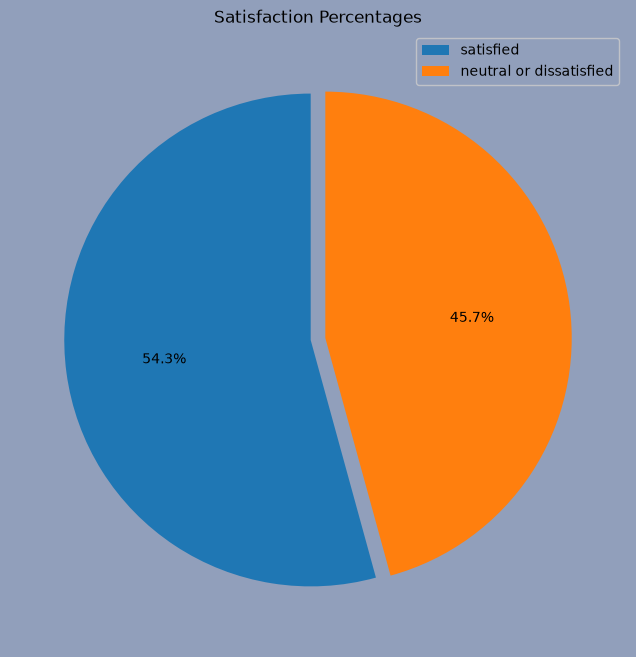

In [66]:
plt.figure(figsize=(8, 8), facecolor="#919fbb")
plt.gca().set_facecolor("#919fbb")
plt.pie(df['satisfaction'].value_counts(),  startangle=90, explode=(0.03, 0.03), autopct='%1.1f%%')
plt.title('Satisfaction Percentages')
plt.legend(df['satisfaction'].value_counts().index, facecolor="#919fbb")
plt.show()

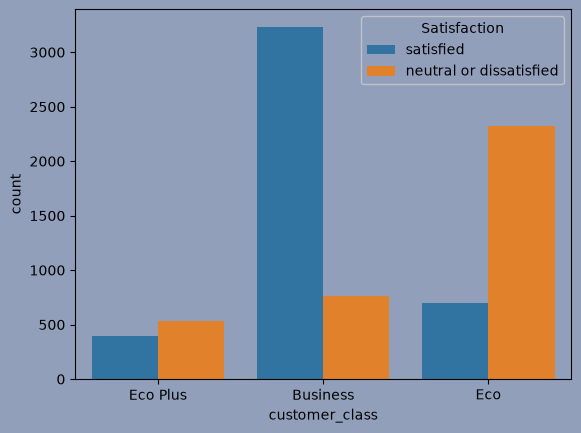

In [67]:
plt.figure().set_facecolor("#919fbb")
plt.gca().set_facecolor("#919fbb")
sns.countplot(x='customer_class', hue='satisfaction', data=df)
plt.legend(title='Satisfaction', facecolor="#919fbb")

### Encoding

- Binary columns are mapped to 0/1: `Gender`, `customer_type` (Loyal = 1), `type_of_travel` (Personal = 1), and the target `satisfaction` (satisfied = 1).
- `customer_class` is ordinal: Eco = 0, Eco Plus = 1, Business = 2.


In [68]:
df['Gender'] = df['Gender'].map({'Male': 1, 'Female': 0})
df['customer_type'] = df['customer_type'].map({'Loyal Customer': 1, 'disloyal Customer': 0})
df['type_of_travel'] = df['type_of_travel'].map({'Personal Travel': 1, 'Business travel': 0})
df['customer_class'] = df['customer_class'].map({'Eco': 0, 'Eco Plus': 1, 'Business': 2})
df['satisfaction'] = df['satisfaction'].map({'satisfied': 1, 'neutral or dissatisfied': 0})
df[categorical_cols].head()

,Gender,customer_type,type_of_travel,customer_class,satisfaction
0,1.0,1.0,1.0,1.0,1
1,0.0,1.0,1.0,2.0,0
2,0.0,1.0,0.0,2.0,1
3,1.0,1.0,0.0,2.0,1
4,1.0,1.0,0.0,2.0,0


### Correlation with satisfaction

- Strongest positive: `customer_class` (0.54), `inflight_entertainment` (0.46), `online_boarding` (0.46).
- Strongest negative: `type_of_travel` (-0.42), meaning personal travel goes with lower satisfaction.
- `age` and `Gender` are almost uncorrelated with satisfaction.


satisfaction                  1.000000
customer_class                0.543181
inflight_entertainment        0.463786
online_boarding               0.458273
baggage_handling              0.427923
leg_room_service              0.424316
onboard_service               0.419682
ease_of_online_booking        0.416074
seat_comfort                  0.404648
cleanliness                   0.391424
inflight_wifi_service         0.379744
customer_type                 0.193225
flight_distance               0.130151
age                           0.000729
Gender                       -0.014442
arrival_delay_in_minutes     -0.081138
departure_delay_in_minutes   -0.090098
type_of_travel               -0.424799
Name: satisfaction, dtype: float64


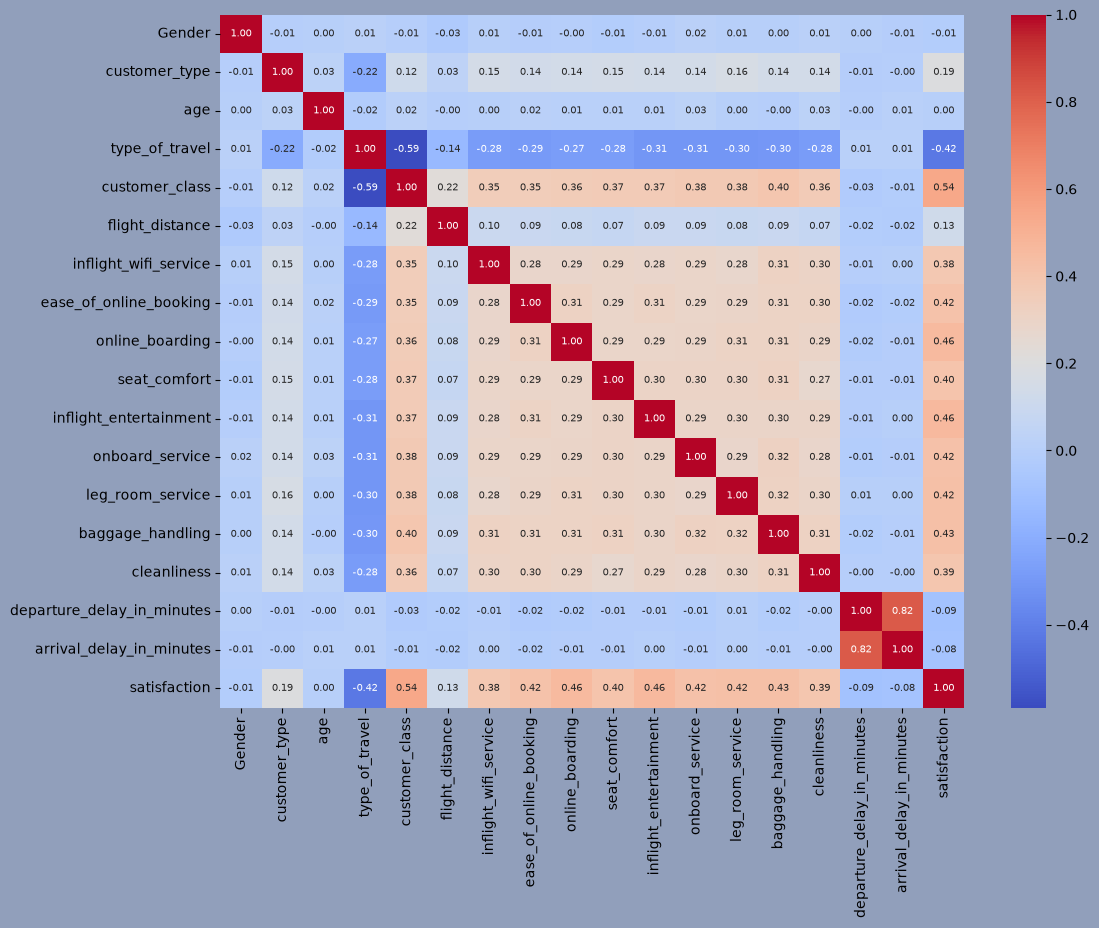

In [69]:
correlation_matrix = df.corr()
corr_by_satisfaction = correlation_matrix['satisfaction'].sort_values(ascending=False)
print(corr_by_satisfaction)

plt.figure(figsize=(12, 9)).set_facecolor("#919fbb")
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", annot_kws={"size": 7})
plt.show()

### Train/test split

80% training, 20% testing (`random_state=42`). The next cell drops rows with a missing target as a safety check (none are missing).


In [70]:
X = df.drop(columns=['satisfaction'])
y = df['satisfaction']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [71]:
X_train = X_train[y_train.notnull()]
X_test = X_test[y_test.notnull()]
y_train = y_train[y_train.notnull()]
y_test = y_test[y_test.notnull()]

In [72]:
X_train.head()

,Gender,customer_type,age,type_of_travel,customer_class,flight_distance,inflight_wifi_service,ease_of_online_booking,online_boarding,seat_comfort,inflight_entertainment,onboard_service,leg_room_service,baggage_handling,cleanliness,departure_delay_in_minutes,arrival_delay_in_minutes
6978,0.0,1.0,48.0,0.0,2.0,7.452402,4.0,5.0,5.0,4.0,5.0,5.0,NaN,4.0,5.0,NaN,0.000000
1507,1.0,1.0,42.0,0.0,2.0,7.448916,3.0,NaN,4.0,5.0,5.0,5.0,4.0,2.0,4.0,2.833213,3.135494
8060,1.0,1.0,40.0,0.0,2.0,NaN,4.0,5.0,NaN,5.0,5.0,4.0,NaN,3.0,4.0,0.000000,0.000000
6216,1.0,1.0,22.0,0.0,2.0,7.315884,4.0,4.0,5.0,5.0,4.0,5.0,4.0,5.0,3.0,NaN,3.218876
5007,0.0,1.0,66.0,0.0,NaN,6.376727,4.0,3.0,2.0,4.0,NaN,1.0,4.0,2.0,NaN,NaN,2.639057


In [73]:
df[categorical_cols].head()

,Gender,customer_type,type_of_travel,customer_class,satisfaction
0,1.0,1.0,1.0,1.0,1
1,0.0,1.0,1.0,2.0,0
2,0.0,1.0,0.0,2.0,1
3,1.0,1.0,0.0,2.0,1
4,1.0,1.0,0.0,2.0,0


### Fill missing values

Using training-set statistics only (to avoid leakage):

- categorical columns: most common value
- numeric columns: median
- rating columns: most common value


In [74]:
X_train[categorical_cols.drop('satisfaction')] = X_train[categorical_cols.drop('satisfaction')].fillna(X_train[categorical_cols.drop('satisfaction')].mode().iloc[0])
X_test[categorical_cols.drop('satisfaction')] = X_test[categorical_cols.drop('satisfaction')].fillna(X_train[categorical_cols.drop('satisfaction')].mode().iloc[0])
X_train[numeric_cols] = X_train[numeric_cols].fillna(X_train[numeric_cols].median())
X_test[numeric_cols] = X_test[numeric_cols].fillna(X_train[numeric_cols].median())
X_train[rating_columns] = X_train[rating_columns].fillna(X_train[rating_columns].mode().iloc[0])
X_test[rating_columns] = X_test[rating_columns].fillna(X_train[rating_columns].mode().iloc[0])

### Scaling and logistic regression

Features are standardized (scaler fitted on the training set only), then a `LogisticRegression` model is trained and used to predict the test set.


In [75]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

model = LogisticRegression()
model.fit(X_train_scaled, y_train)
y_pred = model.predict(X_test_scaled)

### Evaluation

Accuracy, precision, recall and F1 score, plus a confusion matrix. Class 1 (satisfied) is treated as the positive class.


Accuracy: 0.8424170616113744
Precision: 0.8411214953271028
Recall: 0.8775731310942578
F1 Score: 0.8589607635206787


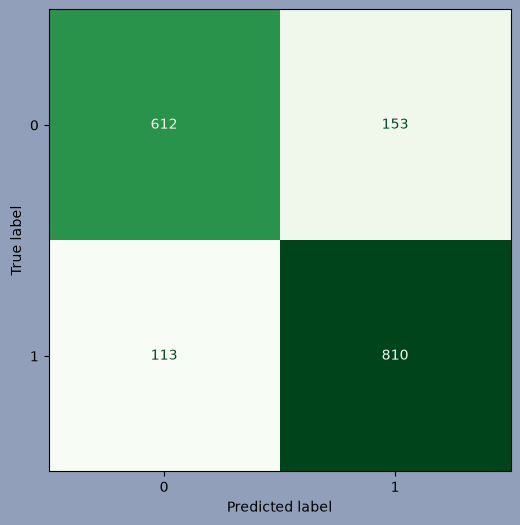

In [76]:
print(f"Accuracy: {accuracy_score(y_test, y_pred)}")
print(f"Precision: {precision_score(y_test, y_pred)}")
print(f"Recall: {recall_score(y_test, y_pred)}")
print(f"F1 Score: {f1_score(y_test, y_pred)}")

plt.figure(figsize=(8, 6), facecolor="#919fbb")
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap='Greens', colorbar=False, ax=plt.gca())
plt.show()